In [97]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
matplotlib.rcParams['axes.unicode_minus']=False

import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression 
from sklearn.preprocessing import PolynomialFeatures # 다항특성 자동생성
from sklearn.linear_model import Ridge
from sklearn.linear_model import Lasso
from sklearn.metrics import mean_absolute_error   # 평균절대값오차 오차범위
from sklearn.preprocessing import StandardScaler  # 정규화클래스
from sklearn.model_selection import train_test_split

In [98]:
# 무게데이터
perch_weight = [5.9, 32.0, 40.0, 51.5, 70.0, 100.0, 78.0, 80.0, 85.0, 85.0,
    110.0, 115.0, 125.0, 130.0, 120.0, 120.0, 130.0, 135.0, 110.0,
    130.0, 150.0, 145.0, 150.0, 170.0, 225.0, 145.0, 188.0, 180.0,
    197.0, 218.0, 300.0, 260.0, 265.0, 250.0, 250.0, 300.0, 320.0,
    514.0, 556.0, 840.0, 685.0, 700.0, 700.0, 690.0, 900.0, 650.0,
    820.0, 850.0, 900.0, 1015.0, 820.0, 1100.0, 1000.0, 1100.0,
    1000.0, 1000.0]

In [99]:
df = pd.read_csv('data/perch_full.csv')
df.head(2)

,length,height,width
0,8.4,2.11,1.41
1,13.7,3.53,2.00


In [100]:
# 데이터 전처리
# 학습데이터, 테스트데이터 분리
train_data,test_data,train_label,test_label = \
train_test_split(df,perch_weight, random_state=42)
train_data[:2]

,length,height,width
8,19.6,5.14,3.04
17,22.0,5.88,3.52


In [101]:
poly = PolynomialFeatures(degree=2,include_bias=False)
poly.fit(train_data)
train_poly = poly.transform(train_data)
test_poly = poly.transform(test_data)

In [102]:
poly.get_feature_names_out()

array(['length', ' height', ' width', 'length^2', 'length  height',
       'length  width', ' height^2', ' height  width', ' width^2'],
      dtype=object)

In [103]:
lr = LinearRegression()
lr.fit(train_poly,train_label)
score = lr.score(train_poly,train_label)
score2 = lr.score(test_poly,test_label)
print('train정확도', score)
print('test정확도', score2)

train정확도 0.9903183436982124
test정확도 0.9714559911594145


In [104]:
ss = StandardScaler()
ss.fit(train_poly)
train_scaled = ss.transform(train_poly)
test_scaled = ss.transform(test_poly)

In [105]:
# alpha는 규제의 강도를 조절해서 확인
alpha_list = [0.001, 0.01, 0.1, 1, 10, 100]
train_score = []
test_score = []
for alpha in alpha_list:
    lasso = Lasso(alpha=alpha)
    lasso.fit(train_poly,train_label)
    score = lasso.score(train_poly,train_label)
    score2 = lasso.score(test_poly,test_label)
    train_score.append(score)
    test_score.append(score2)

c:\python313\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.926363e+04, tolerance: 5.183e+02
  model = cd_fast.enet_coordinate_descent(
c:\python313\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.927420e+04, tolerance: 5.183e+02
  model = cd_fast.enet_coordinate_descent(
c:\python313\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.932417e+04, tolerance: 5.183e+02
  model = cd_f

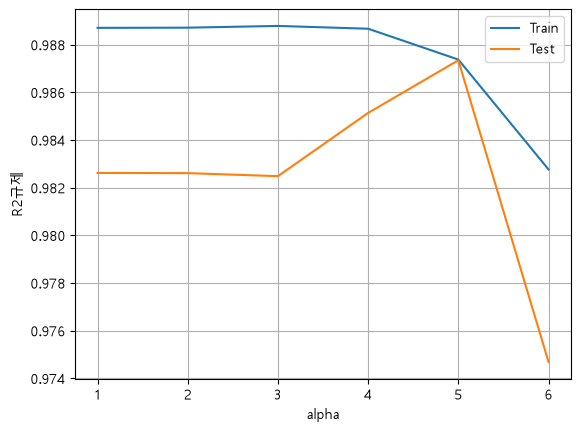

In [109]:
no_list = list(range(1,7))
plt.plot(no_list,train_score)
plt.plot(no_list,test_score)
plt.grid() # 눈금
plt.legend(['Train','Test'])
plt.xlabel("alpha")
plt.ylabel("R2규제")
plt.show()

In [ ]:
lasso = Lasso(alpha=10)
lasso.fit(train_scaled,train_label)
score = lasso.score(train_scaled,train_label)
score2 = lasso.score(test_scaled,test_label)
print('train정확도', score)
print('test정확도', score2)
print(np.sum(lasso.coef_)) # 사용하지 않는 특성 -> 사용하지 않는 것이 많아서 Lasso는 많이 사용하지 않음. Ridge를 많이 씀

train정확도 0.9827254657543516
test정확도 0.9778291802263332
339.13948486304804
